# 02 · Execution simulation

Parent orders of 1/5/10/20% of ADV, worked by TWAP, VWAP, POV 10%, POV 20% and IS (Almgren-Chriss, urgency 3) on every session, as buys and sells. Fill model and decomposition: `src/execution/simulator.py`, `src/tca/analysis.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import UNIVERSE, FX_TICKER, RESULTS_DIR
from src.reporting import charts
R = lambda name: pd.read_csv(RESULTS_DIR / name)
import plotly.io as pio
pio.renderers.default = "png"  # static images so the notebooks render on GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 900, 480

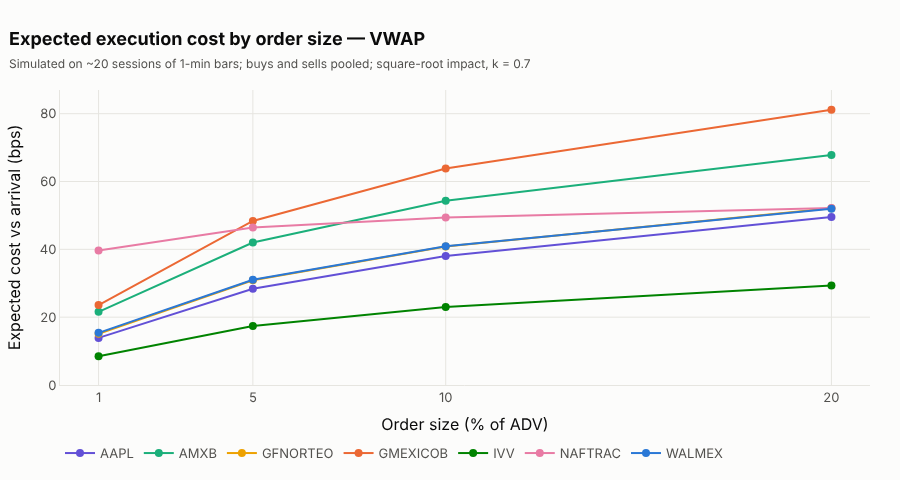

In [2]:
costs = R('cost_table.csv')
charts.cost_curve(costs, 'VWAP').show()

In [3]:
costs.pivot_table(index=['ticker','pct_adv'], columns='algo', values='is_total_bps').round(1)

algo                       IS  POV10  POV20  TWAP  VWAP
ticker          pct_adv                                
AAPL            0.01     15.3   33.4   46.0  14.6  13.9
                0.05     31.0   32.1   45.5  29.9  28.4
                0.10     41.1   28.6   45.0  39.8  38.0
                0.20     52.8   34.0   40.6  51.4  49.5
AMXB.MX         0.01     26.8   37.1   51.4  22.0  21.6
                0.05     49.5   35.1   51.6  42.9  42.0
                0.10     61.8   32.5   50.0  55.4  54.3
                0.20     74.3   42.9   45.0  68.8  67.8
GFNORTEO.MX     0.01     20.0   30.9   43.4  16.0  15.1
                0.05     38.6   28.4   42.5  32.7  30.9
                0.10     49.0   26.2   40.6  42.9  40.8
                0.20     59.7   33.7   37.4  54.3  52.1
GMEXICOB.MX     0.01     32.4   46.1   64.9  25.1  23.6
                0.05     61.8   43.3   64.1  51.0  48.4
                0.10     77.6   39.4   61.6  66.9  63.8
                0.20     93.5   52.0   55.8  84.2  81.2
IVV             0.01      9.8   16.9   23.7   8.7   8.5
                0.05     19.7   15.7   23.6  17.8  17.4
                0.10     25.5   14.7   22.8  23.5  23.0
                0.20     31.8   19.0   20.8  29.8  29.4
NAFTRACISHRS.MX 0.01     46.4   19.3   26.8  41.6  39.7
                0.05     51.8   18.1   24.0  48.0  46.4
                0.10     53.7   20.9   24.1  50.6  49.4
                0.20     55.4   27.3   27.8  53.0  52.2
WALMEX.MX       0.01     21.0   30.2   42.2  16.2  15.4
                0.05     39.5   28.8   41.8  32.5  31.1
                0.10     49.5   26.0   41.0  42.4  40.9
                0.20     59.6   33.5   36.7  53.5  52.0

Risk (std of implementation shortfall across orders) is the other half of the decision:

In [4]:
costs.pivot_table(index=['ticker','pct_adv'], columns='algo', values='is_std_bps').round(0)

algo                        IS  POV10  POV20   TWAP   VWAP
ticker          pct_adv                                   
AAPL            0.01      99.0   51.0   38.0  111.0  103.0
                0.05      99.0   84.0   66.0  112.0  103.0
                0.10      99.0  103.0   81.0  112.0  103.0
                0.20      99.0  110.0  100.0  112.0  103.0
AMXB.MX         0.01     138.0   84.0   64.0  157.0  160.0
                0.05     139.0  141.0  107.0  157.0  160.0
                0.10     139.0  160.0  134.0  157.0  160.0
                0.20     139.0  177.0  157.0  157.0  160.0
GFNORTEO.MX     0.01      77.0   69.0   58.0   95.0   97.0
                0.05      77.0  102.0   85.0   95.0   97.0
                0.10      77.0  123.0   98.0   95.0   97.0
                0.20      77.0  136.0  120.0   95.0   97.0
GMEXICOB.MX     0.01     100.0  100.0   98.0  106.0  106.0
                0.05     100.0  115.0  111.0  106.0  106.0
                0.10     100.0  120.0  114.0  106.0  106.0
                0.20     100.0  124.0  119.0  106.0  106.0
IVV             0.01      70.0   34.0   17.0   85.0   84.0
                0.05      70.0   66.0   49.0   85.0   84.0
                0.10      70.0   76.0   63.0   85.0   84.0
                0.20      70.0   88.0   74.0   85.0   84.0
NAFTRACISHRS.MX 0.01      52.0   60.0   62.0   54.0   56.0
                0.05      52.0   58.0   59.0   54.0   56.0
                0.10      52.0   58.0   58.0   54.0   56.0
                0.20      52.0   59.0   58.0   54.0   56.0
WALMEX.MX       0.01     117.0  104.0   83.0  134.0  136.0
                0.05     117.0  140.0  132.0  134.0  136.0
                0.10     117.0  145.0  141.0  134.0  136.0
                0.20     117.0  151.0  144.0  134.0  136.0

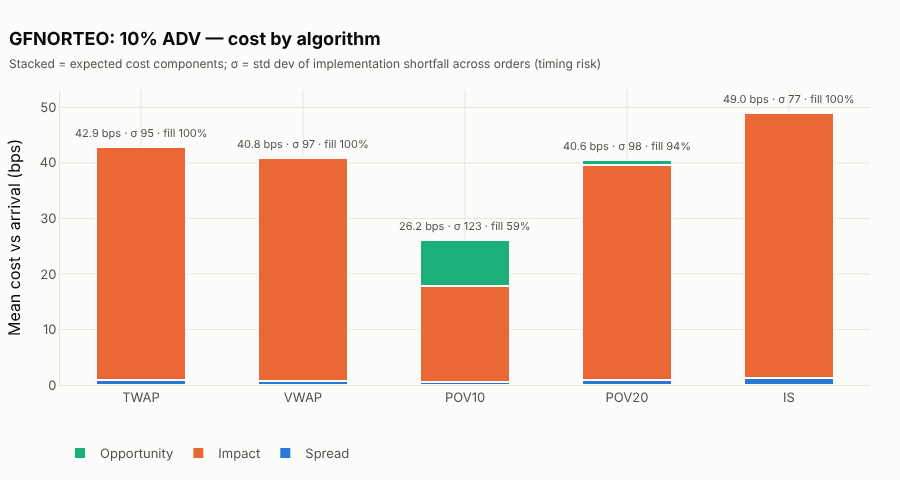

In [5]:
charts.algo_decomposition(costs, 'GFNORTEO.MX', 0.10).show()

## One order, end to end

In [6]:
from src.data.loaders import load_enriched
from src.data.yf_loader import load_yf_daily
from src.execution.simulator import TickerContext, spread_curve_bps, run_order
b = load_enriched('GFNORTEO.MX')
ctx = TickerContext('GFNORTEO.MX', b, load_yf_daily('GFNORTEO.MX'), spread_curve_bps(b, 0.99))
summary, fills = run_order(ctx, ctx.dates[-1], 'vwap', 0.10, side=+1)
pd.Series(summary)

ticker               GFNORTEO.MX
date                  2026-11-13
algo                        VWAP
pct_adv                      0.1
side                           1
qty                       806362
adv                    8063621.5
sigma_bps             127.442452
arrival_px            213.190002
avg_px                210.512399
vwap_px               208.572569
close_px              205.440002
vs_arrival_bps       -125.597031
vs_vwap_bps            93.005044
vs_close_bps          246.904051
duration_min                 329
avg_participation       0.233439
timing_bps           -173.997163
spread_bps              0.910061
impact_bps             47.490072
opportunity_bps              0.0
is_total_bps         -125.597031
is_filled_bps        -125.597031
fill_rate                    1.0
dtype: object

In [7]:
fills[fills.qty > 0].head(10)

,timestamp,minute_of_session,qty,ref_px,fill_px,half_spread_bps,impact_bps,participation,market_volume
0,2026-11-13 08:31:00-06:00,1,3349.0,213.203328,214.595319,2.581906,62.707422,0.494099,3429.0
1,2026-11-13 08:32:00-06:00,2,3258.0,213.350001,214.644042,2.581906,58.071547,0.423743,5556.0
2,2026-11-13 08:33:00-06:00,3,3246.0,213.183334,214.469352,2.581906,57.742583,0.418956,4680.0
3,2026-11-13 08:34:00-06:00,4,3209.0,213.190002,214.561112,2.581906,61.732055,0.478847,551.0
4,2026-11-13 08:35:00-06:00,5,3129.0,213.078334,214.464616,2.581906,62.477872,0.490488,2603.0
5,2026-11-13 08:36:00-06:00,6,3155.0,213.010000,214.431619,2.581906,64.157656,0.517217,1542.0
6,2026-11-13 08:37:00-06:00,7,3103.0,212.960007,214.514830,2.581906,70.428181,0.623259,200.0
7,2026-11-13 08:38:00-06:00,8,3180.0,212.863332,214.521686,2.581906,75.325067,0.712943,1456.0
8,2026-11-13 08:39:00-06:00,9,3003.0,212.899994,214.568829,2.581906,75.803944,0.722037,193.0
9,2026-11-13 08:40:00-06:00,10,2985.0,212.586665,214.215849,2.581906,74.054349,0.689091,3569.0


Identity check: timing + spread + impact + opportunity = total shortfall.

In [8]:
o = pd.read_csv(RESULTS_DIR / 'orders.csv.gz')
(o[['timing_bps','spread_bps','impact_bps','opportunity_bps']].sum(axis=1) - o['is_total_bps']).abs().max()

np.float64(1.1368683772161603e-13)